# Spitzer Stellar PSF Photometry


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `spitzer_stellar_psf_photometry` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：images (1, 4, 17, 17) float64：Observed survey surface brightness in MJy/sr; axes batch, patch, row, column；flight_psf (1, 81, 81) float64：Independent focus-star PSF samples, dimensionless normalized calibration weights; axes batch, row, column。恢复目标：四source subpixel positions、PSF amplitude和local sky。

获取模型：独立flight PSF经cubic interpolation/subpixel shift采样，乘source amplitude再加constant sky。实际恢复算法：solvers.reconstruct逐patch有界least_squares四参数；prepare_psf按物理sampling处理PSF。语义类型为 `inverse_parameter`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:136/137无actual source truth；baseline为original独立fit，flight PSF是校准。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：spitzer_stellar_psf_photometry.ipynb单元6：5. Results；spitzer_stellar_psf_photometry.ipynb单元8有保存图；im=ax.imshow(a,origin='lower');ax.set_title(label,fontsize=10);fig.colorbar(im,ax=ax)；spitzer_stellar_psf_photometry.ipynb单元12有保存图；图内容由该单元调用的本地visualization函数生成；spitzer_stellar_psf_photometry.ipynb单元14有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元8, 12, 14（从0计数）。代码单元5个，带execution_count的5个，保存PNG输出3幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


Active maintainer reconstruction and independently identified scientific comparisons.


## 1. Problem

Estimate subpixel source position, amplitude and local sky jointly in four real
Spitzer 4.5 micrometre star patches. A finite sampled PSF spreads source light;
subpixel motion changes that sampling while diffuse sky and optical mismatch
couple position and amplitude. No source catalog is supplied as an input.

Save `output/reconstruction.npz` with float64 `positions` **(1,4,2)** [pixel],
final axis x-column, y-row; `flux` **(1,4)** [MJy/sr times image pixel]; and
`background` **(1,4)** [MJy/sr]. Preserve patch order and finite absolute scales;
positions lie in [0,16], amplitude is nonnegative. These are local zero-based
pixel-center coordinates, without source reassignment or fitted alignment.
The amplitude is not already Jy and the instrument PSF is an explicit adopted
model. No independently known stellar positions/fluxes or detector variance
map makes either fit physical truth.


## 2. Data

The image is a real GLIMPSE survey channel 2 mosaic,
`spitzer_example_image.fits`, internal FITS product
`GLM_01800+0000_mosaic_I2.fits`, from
https://github.com/astropy/photutils-datasets at remotely verified commit
`8c97b4fa3a6c9e6ea072faeed2d49a20585658ba`. Independently recorded
`irac_ch2_flight.fits` is the IOC/SV campaign Q focus-star calibration.
Both commit-pinned downloads were byte-checked. The survey product was created on
2006-12-02; the calibration product was created on 2004-01-02. This is processed, mosaicked
surface brightness, not raw detector exposures or a synthetic blurred photo.

Four 17-by-17 cutouts have original zero-based (row, column) centers
(294,216),(479,87),(226,788),(104,324). Values are exactly promoted from
float32 FITS to float64 without brightness rescaling. Selection scanned
interior 21-by-21 local maxima with peak 200..1500 MJy/sr and kept the four
smallest original one-source model residuals before local extraction. This
defines isolated-source applicability and introduces selection bias; it is not
a claim about all crowded stars or independently verified saturation flags.
The flight PSF was not estimated from these sources. The original method is
Photutils 2.3.0 `ImagePSF` plus Astropy 8.0.2 bounded TRF, Photutils commit
`f060288dd9ece60c3ef11f5b7d45809ee845612d`. NASA factual educational-use
terms and mission/IRSA attributions are retained in the validation license
record; the data repository has no independent blanket dataset license.

The separate flight calibration is supplied in its original sampling and values.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| images | (1, 4, 17, 17) | float64 | Observed survey surface brightness in MJy/sr; axes batch, patch, row, column |
| flight_psf | (1, 81, 81) | float64 | Independent focus-star PSF samples, dimensionless normalized calibration weights; axes batch, row, column |

### Acquisition metadata

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Telescope / instrument | Spitzer / IRAC channel 2 | dimensionless | Infrared survey instrument |
| Nominal wavelength | 4.5 | micrometre | Channel band designation |
| Survey product | GLM_01800+0000_mosaic_I2 | dimensionless | Processed GLIMPSE mosaic; not raw detector exposures |
| Mosaic creation | 2006-12-02 | UTC date | FITS product creation date |
| Mosaic pixel scale | 1.2 | arcsec/pixel | Both output image axes |
| Native frame pixel scale | 1.213 | arcsec/pixel | Single-exposure sampling before mosaicking |
| FITS effective integration time | 1.2 | s | Exposure metadata; not an independent noise variance for the mosaic |
| Flight PSF pixel spacing | 0.30325 | arcsec/sample | Fourfold oversampling of native detector pixels |
| Flight PSF provenance | IOC/SV campaign Q focus star; product 2004-01-02 | dimensionless | Independent calibration observation |
| Adopted PSF resampling | 0.3 | arcsec/sample | Fourfold oversampling relative to the mosaic |
| PSF center and support | (40,40); 81 by 81 | calibration samples | Zero-based center, exact spline inside grid and zero outside |
| Resampled PSF sum | 16 | dimensionless | Oversampling-squared normalization |
| Image coordinate convention | x column, y row; zero-based pixel centers | pixel | Patch-local coordinates; array row increases with y |
| Noise covariance | Not supplied | dimensionless | Correlated mosaic noise is possible; adopt unweighted least squares without assuming a known variance |
| Boundary and background | Zero PSF outside support; constant additive sky per patch | MJy/sr for sky | Finite calibration support; no periodic boundaries |



In [1]:
from pathlib import Path
import sys, time, json, importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').is_dir(): root=root.parent
assert (root/'data/raw_data.npz').is_file()
sys.path.insert(0,str(root))
from src.preprocessing import load_data, prepare_psf, initialize
from src.physics_model import make_interpolator, model
from src.solvers import reconstruct
from src.visualization import compare
images,flight=load_data(root/'data/raw_data.npz')
print('observed patches:',images.shape,'independent calibration:',flight.shape)
with np.load(root/'data/raw_data.npz',allow_pickle=False) as visible:
    print('Visible acquisition arrays (batch first on disk):')
    for key in visible.files: print(key,visible[key].shape,str(visible[key].dtype))


observed patches: (4, 17, 17) independent calibration: (81, 81)
Visible acquisition arrays (batch first on disk):
images (1, 4, 17, 17) float64
flight_psf (1, 81, 81) float64


## 3. Physics

At row j, column i in patch k the adopted model is


$$
D_k[j,i]=F_kP(i-x_k,j-y_k)+b_k+e_k[j,i].
$$


D,b are MJy/sr, positions in image pixels, F is MJy/sr times image pixel, and e
includes noise, source contamination, sky structure and effective PSF mismatch.
The flight PSF spacing h=.30325 arcsec differs from fourfold oversampling of
the mosaic, d=1.2 arcsec. Let B be its exact cubic tensor-product spline centered
at (40,40). Resample at a(u)=40+(u-40)*(.3/.30325),u=0..80, then normalize
the 81-by-81 result Q to sum 16. Preserve signed calibration sidelobes.

Let S be the exact cubic spline of Q in (column, row) order. Define
P(a,c)=S(40+4a,40+4c) inside [0,80] on each calibration axis, zero outside.
There is no periodic extension, rotation, extra smoothing or second pixel-area
integration: the calibration already includes instrument pixel response.
Sum Q/16=1 matches ImagePSF normalization; output pixel-center sampled sum
can vary slightly with subpixel phase/support, so F is the adopted model's
amplitude, not independently accurate aperture photometry.

Approximate pixel solid angle Omega=(1.2/206264.806247)^2sr gives a Jy
conversion F*1e6*Omega, unused in fitting/evaluation. The 2004 focus-star PSF
is assumed to represent the 2006 mosaic response; mosaicking, orientation/field
variation and calibration epoch can leave structured residuals. No target-star
empirical calibration or independent true flux is hidden in the observations.


## 4. Method

Fit each patch independently by unweighted sum(M-D)^2 over all 289 pixels,
without mask, regularizer, robust loss or known noise weighting. Use the first
row-major maximum for initial position, the median of unique boundary pixels for
initial sky, and sum max(D-sky,0) for initial amplitude. Bound F>=0 and each
position within two pixels of its initial peak; sky remains unbounded.

The original Photutils ImagePSF+constant model and Astropy TRFLSQFitter use
the same generic SciPy trust-region backend as the local explicit residual:
method='trf', two-point Jacobian, relative diff_step=sqrt(float64 epsilon),
max_nfev=200,xtol=1e-10,ftol=gtol=1e-8; no custom x_scale is passed.
TRF linearizes model residuals, selects bounds-aware steps in a trust region,
adjusts radius based on actual/predicted reduction and tests cost/step/gradient
convergence. A failed success flag raises RuntimeError. All four original fits terminate
by ftol in 9, 9, 9, 10 function evaluations. No empirical PSF, refit or catalog update
or alternate inverse stage is hidden in these steps.

Independent derivatives explain the model checks: dM/dF=P, dM/db=1,
dM/dx=-4F*S_x, dM/dy=-4F*S_y inside support. Central objective differences,
known-source recovery, one-pixel translation and brightness linearity validate
these beyond duplicated formulas. Frozen original calibration/initialization/
model/final parameter arrays establish numerical parity.

Original double repeats agree exactly. A separate float32 PSF precision run gives
maximum position 1.4987535863424255e-8 pixel, maximum relative amplitude 1.1003613781237246e-8,
maximum sky 4.0027259196051546e-7 MJy/sr. Before extraction boundaries were fixed at
1e-5 pixel, 1e-5 relative amplitude, 1e-4 MJy/sr sky, plus global observation relative L2
<=.12. None is an astrophysical uncertainty interval. Retain the newly
evaluated peak/border initialization comparison, independently reproduced original
fit and actively computed local fit as distinct method groups.


## 5. Results

Every fresh reconstruction and comparison here is computed from the loaded real
observations using local src modules. Independent original-code outputs are
labeled references, never physical truth. Previously packaged snapshots are
kept byte-frozen; this execution's runtime and evidence are captured privately.
Display normalization affects figure contrast only, not quantitative arrays.

Position/amplitude/sky parameter equality is numerical method agreement. The common MJy/sr image residual retains model mismatch, while the initialization-versus-fit comparison demonstrates optimization improvement without supplying a true source catalogue.


### Independent flight and physically resampled adopted PSF


Original calibration sum: 0.999999996322208 adopted sum: 16.0


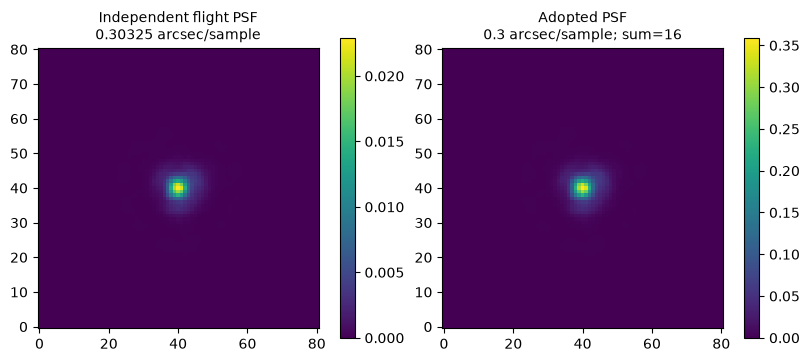

In [2]:
effective=prepare_psf(flight)
fig,axes=plt.subplots(1,2,figsize=(8,3.5),constrained_layout=True)
for ax,a,label in zip(axes,[flight,effective],['Independent flight PSF\n0.30325 arcsec/sample','Adopted PSF\n0.3 arcsec/sample; sum=16']):
 im=ax.imshow(a,origin='lower');ax.set_title(label,fontsize=10);fig.colorbar(im,ax=ax)
print('Original calibration sum:',flight.sum(),'adopted sum:',effective.sum())
plt.show()

### Fresh four-source joint inverse fit


In [3]:
start=time.perf_counter()
submission,fresh=reconstruct(images,flight)
runtime=time.perf_counter()-start
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz',**submission)
print('Fresh CPU reconstruction seconds:',runtime)
print('positions (x,y), pixel:',submission['positions'][0])
print('amplitude, MJy/sr pixel:',submission['flux'][0])
print('sky, MJy/sr:',submission['background'][0])

Fresh CPU reconstruction seconds: 0.016605400014668703
positions (x,y), pixel: [[7.71301296 8.34477388]
 [7.82646319 8.46972087]
 [7.80791373 8.48721613]
 [7.85240964 7.65869899]]
amplitude, MJy/sr pixel: [4473.45661352 4509.92643514 4303.41587417 4181.40519295]
sky, MJy/sr: [6.00346922 5.04677293 5.68582916 4.38317278]


### All four observed/original/fresh/residual rows and full parameter table


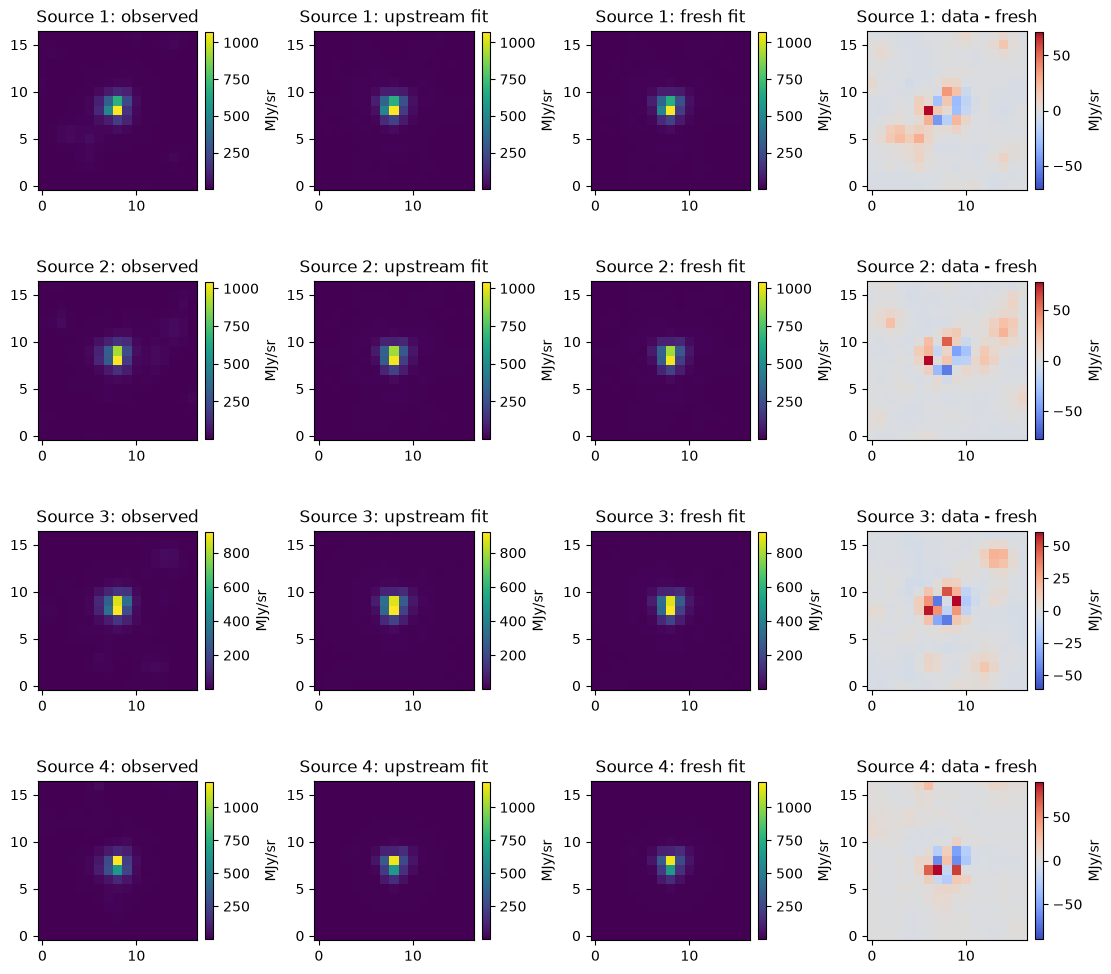

Method / source / amplitude [MJy/sr pixel] / x [pixel] / y [pixel] / sky [MJy/sr]
peak-border initialization (fresh) 1 4791.338148 8 8 5.067862034
peak-border initialization (fresh) 2 4818.763758 8 8 4.148454905
peak-border initialization (fresh) 3 4726.732815 8 8 4.334784985
peak-border initialization (fresh) 4 4250.086038 8 8 4.448073387
original-library reproduced fit 1 4473.456614 7.713012955 8.344773879 6.003469216
original-library reproduced fit 2 4509.926435 7.826463191 8.469720869 5.046772928
original-library reproduced fit 3 4303.415874 7.807913731 8.487216133 5.685829161
original-library reproduced fit 4 4181.405193 7.852409639 7.658698985 4.383172776
local fit (fresh) 1 4473.456614 7.713012955 8.344773879 6.003469216
local fit (fresh) 2 4509.926435 7.826463191 8.469720869 5.046772928
local fit (fresh) 3 4303.415874 7.807913731 8.487216133 5.685829161
local fit (fresh) 4 4181.405193 7.852409639 7.658698985 4.383172776


In [4]:
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as archive:
 upstream=archive['model'].copy(); upstream_parameters=archive['parameters'].copy()
initial=np.stack([initialize(a) for a in images])
interpolator=make_interpolator(effective)
initial_images=np.stack([model(p,interpolator) for p in initial])
fig=compare(images,upstream,fresh)
plt.show()
fresh_parameters=np.column_stack([submission['flux'][0],submission['positions'][0],submission['background'][0]])
print('Method / source / amplitude [MJy/sr pixel] / x [pixel] / y [pixel] / sky [MJy/sr]')
for name,parameters in [('peak-border initialization (fresh)',initial),('original-library reproduced fit',upstream_parameters),('local fit (fresh)',fresh_parameters)]:
 for i,p in enumerate(parameters):print(name,i+1,*[f'{v:.10g}' for v in p])

### Paired initialization/original/fresh residual bars and independent Judge


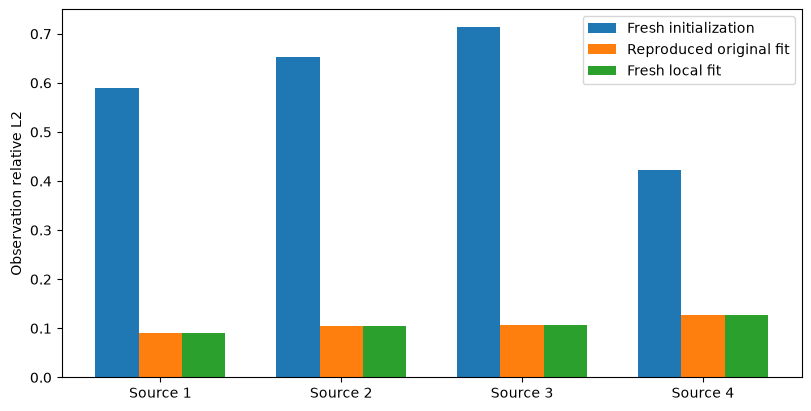

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "position_error": 0.0,
    "flux_relative_error": 0.0,
    "background_absolute_error": 0.0,
    "observation_relative_l2": 0.10814110360050014
  },
  "thresholds": {
    "position_error": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "flux_relative_error": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "background_absolute_error": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "observation_relative_l2": {
      "comparison": "<=",
      "boundary": 0.12
    }
  },
  "errors": []
}


In [5]:
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
q=np.arange(4)
for offset,name,stack in [(-.24,'Fresh initialization',initial_images),(0,'Reproduced original fit',upstream),(.24,'Fresh local fit',fresh)]:
 errors=np.linalg.norm(stack-images,axis=(1,2))/np.linalg.norm(images,axis=(1,2))
 ax.bar(q+offset,errors,width=.24,label=name)
ax.set_xticks(q,[f'Source {i+1}' for i in q]);ax.set_ylabel('Observation relative L2');ax.legend();plt.show()
spec=importlib.util.spec_from_file_location('review_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(root/'output/reconstruction.npz')
print(json.dumps(report,indent=2));assert exit_code==0
manual=float(np.linalg.norm(fresh-images)/np.linalg.norm(images))
assert abs(manual-report['metrics']['observation_relative_l2'])<1e-14
assert np.max(np.abs(fresh-upstream))<1e-8

## 6. Conclusion

Fresh local source positions, amplitudes and skies agree exactly with the
separately run original method on this environment. The observed model relative L2
is 0.10814110360050014; paired initialization/original/fresh bars show the fit's
improvement while the image grid retains structured residuals. Zero parameter
discrepancy establishes algorithm reproduction, not zero model error.

The 2004 flight PSF is an imperfect assumption for the 2006 processed mosaic;
angular sampling correction does not remove field variation, resampling effects,
neighboring faint sources or sky structure. There is no detector variance map,
independent truth catalog or astrophysical uncertainty interval. The fitted
amplitude remains MJy/sr times image pixel, with only the approximate solid angle
Jy conversion stated above. The selected isolated patches do not establish
crowded-field completeness or survey-wide photometric accuracy.

Source provenance, independent original-run evidence, tests, precise parameter conventions and preserved copyright/license records: `test/validation.md`; executable mathematical and interface detail: `plan/approach.md` and `plan/design.md`.
